# Rasio Keuangan & Peer Comparison per Sektor | Combined Financial Data IDX

**Mikail Achmad: EDA Laporan Keuangan Emiten IDX (2020–2023)**
*(Untuk Data Analyst Internship at SOKO Financial)*

Notebook ini merupakan **tahap ketiga**, yang melanjutkan *Data Overview & Quality* dan *Financial Metrics Breakdown & Tren YoY*. Kalau dua notebook sebelumnya berhenti di angka mentah (pendapatan, laba, aset), di notebook ini angka-angka itu kita olah jadi **rasio**, sebagai alat baku untuk menilai *sehat atau tidaknya* sebuah perusahaan, lalu dibandingkan **antar sektor**.

**Menapa ini paling kepake untuk SOKO Financial?** Rasio menyetarakan emiten besar dan kecil ke ukuran yang sebanding, sehingga bisa jadi dasar untuk **menyaring** (screening) emiten mana yang layak dinilai lebih lanjut.

**Tujuan notebook ini**
1. Menghitung rasio kunci: **profitabilitas** (ROE, ROA, Net Margin), **solvabilitas** (DER), **likuiditas** (Current Ratio), plus dekomposisi **DuPont** untuk ROE.
2. Memisahkan emiten **keuangan dengan non keuangan**, karena struktur neracanya berbeda.
3. Membandingkan rasio **antar sektor riil** (peer comparison) untuk potret 2023 serta tren dari tahun 2020 hingga tahun 2023.
4. Menunjukkan contoh **screening** emiten layak berbasis rasio.

## 1. Setup & Load Data

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)

BLUE  = "#2a78d6"
AQUA  = "#1baf7a"
RED   = "#d03b3b"
AMBER = "#eda100"
INK   = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID  = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

def style_ax(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

def bar_labels(ax, bars, fmt="{:.1f}", pad=0.3, horizontal=False):
    for b in bars:
        if horizontal:
            w = b.get_width()
            ax.text(w + pad, b.get_y() + b.get_height()/2, fmt.format(w),
                    va="center", ha="left", fontsize=9.5, color=INK, fontweight="600")
        else:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + pad, fmt.format(h),
                    va="bottom", ha="center", fontsize=9.5, color=INK, fontweight="600")

In [3]:
# Data sumber yaitu data keuangan (long) dan metadata pasar (sektor, industri, harga)
df   = pd.read_csv("combined_financial_data_idx.csv")
meta = pd.read_csv("idx_market_metadata.csv")
years = ["2020", "2021", "2022", "2023"]

print("Data keuangan :", df.shape)
print("Metadata pasar:", meta.shape, "| kolom:", list(meta.columns))
meta.head(3)

Data keuangan : (89243, 7)
Metadata pasar: (604, 8) | kolom: ['symbol', 'company_name', 'sector', 'industry', 'price_2020', 'price_2021', 'price_2022', 'price_2023']


,symbol,company_name,sector,industry,price_2020,price_2021,price_2022,price_2023
0,AALI,PT Astra Agro Lestari Tbk,Consumer Defensive,Farm Products,9410.87,7446.98,6535.04,6019.42
1,ABBA,PT Mahaka Media Tbk,Communication Services,Publishing,65.15,281.27,151.00,52.00
2,ABDA,PT Asuransi Bina Dana Arta Tbk,Financial Services,Insurance - Property & Casualty,5446.37,5769.86,6700.00,5800.00


## 2. Menyusun Tabel Analitik (per Emiten per Tahun)

Data keuangan masih berformat satu baris mencakup satu akun. Untuk menghitung rasio, kita *pivot* menjadi: satu baris mencakup satu emiten pada satu tahun, kolom = akun. Lalu kita gabungkan dengan metadata **sektor & industri** agar dapat peer comparison.

**Catatan penting sebagai pemisahan keuangan vs non-keuangan:** Emiten keuangan (bank, asuransi, multifinance) punya struktur neraca yang berbeda. Mereka tidak melaporkan *Working Capital* / aset liabilitas lancar seperti perusahaan biasa, dan rasio utang mereka wajar jika sangat tinggi. 

Kita tandai emiten keuangan lewat *Working Capital* yang kosong, agar rasio solvabilitas/likuiditas membandingkan secara lebih _fair_.

In [4]:
# Long dan wide (satu baris = symbol x year)
melted = df.melt(id_vars=["symbol", "account", "type"],
                 value_vars=years, var_name="year", value_name="value")
piv = melted.pivot_table(index=["symbol", "year"], columns="account",
                         values="value").reset_index()

# Gabung metadata sektor/industri/nama
piv = piv.merge(meta[["symbol", "company_name", "sector", "industry"]],
                on="symbol", how="left")

# Flag struktural pada Emiten keuangan
piv["is_financial"] = piv["Working Capital"].isna()
piv["kelompok"] = np.where(piv["is_financial"], "Keuangan", "Non Keuangan")

print(f"Baris analitik (symbol x year): {len(piv):,}")
print(f"Kolom akun tersedia           : {piv.shape[1]}")
print()
print("Komposisi per tahun (Keuangan dengan Non Keuangan):")
print(pd.crosstab(piv["year"], piv["kelompok"]))

Baris analitik (symbol x year): 2,319
Kolom akun tersedia           : 271

Komposisi per tahun (Keuangan dengan Non Keuangan):
kelompok  Keuangan  Non Keuangan
year                            
2020            67           528
2021            67           529
2022            70           522
2023            87           449


## 3. Menghitung Rasio Kunci

Lima rasio inti plus dekomposisi DuPont. Semua pembagi nol diganti `NaN` terlebih dahulu.

| Rasio | Rumus | Arti singkat |
|---|---|---|
| **ROE** (Return on Equity) | Laba Bersih ÷ Ekuitas | Seberapa untung dibanding **modal** pemegang saham |
| **ROA** (Return on Assets) | Laba Bersih ÷ Total Aset | Seberapa untung dibanding **aset** yang dikelola |
| **Net Margin** | Laba Bersih ÷ Pendapatan | Berapa % pendapatan yang jadi laba |
| **DER** (Debt-to-Equity) | Total Liabilitas ÷ Ekuitas | Seberapa besar **utang dibanding modal** |
| **Current Ratio** | Aset Lancar ÷ Liabilitas Lancar | Kemampuan bayar kewajiban jangka pendek |

**Dekomposisi DuPont:** `ROE = Net Margin × Asset Turnover × Equity Multiplier` yang akan memisah sumber ROE jadi *efisiensi laba*, *efisiensi aset*, dan *leverage*.

Ekuitas yang dipakai yaitu `Stockholders Equity`.

In [5]:
EQ   = "Stockholders Equity"
LIAB = "Total Liabilities Net Minority Interest"

# Profitabilitas
piv["ROE"]        = piv["Net Income"] / piv[EQ].replace(0, np.nan) * 100
piv["ROA"]        = piv["Net Income"] / piv["Total Assets"].replace(0, np.nan) * 100
piv["NetMargin"]  = piv["Net Income"] / piv["Total Revenue"].replace(0, np.nan) * 100

# Solvabilitas & Likuiditas
piv["DER"]          = piv[LIAB] / piv[EQ].replace(0, np.nan)
piv["CurrentRatio"] = piv["Current Assets"] / piv["Current Liabilities"].replace(0, np.nan)

# Komponen DuPont (ROE = margin x turnover x leverage)
piv["dupont_margin"]   = piv["Net Income"] / piv["Total Revenue"].replace(0, np.nan)
piv["asset_turnover"]  = piv["Total Revenue"] / piv["Total Assets"].replace(0, np.nan)
piv["equity_mult"]     = piv["Total Assets"] / piv[EQ].replace(0, np.nan)

# Flag kualitas: ekuitas negatif bikin ROE & DER menyesatkan
piv["neg_equity"] = piv[EQ] < 0

print("Emiten dengan ekuitas negatif per tahun:")
print(piv[piv["neg_equity"]].groupby("year").size())

Emiten dengan ekuitas negatif per tahun:
year
2020    34
2021    34
2022    36
2023    20
dtype: int64


> **Catatan metodologi.** Dua penyesuaian penting sebelum membandingkan:
> 1. **Ekuitas negatif**: ROE dan DER kehilangan makna (ROE bisa positif dari dua angka negatif). Emiten ini **dikecualikan** dari analisis ROE/DER, tapi tetap dicatat jumlahnya.
> 2. **DER & Current Ratio** hanya dibandingkan pada emiten **nonkeuangan**. Bank/asuransi punya struktur modal yang beda kelas. ROE/ROA tetap ditampilkan untuk kedua kelompok secara terpisah.

In [6]:
# Potret terbaru 2023 dan subset bersih untuk perbandingan
y23 = piv[piv["year"] == "2023"].copy()

# Non-keuangan, ekuitas positif menjadi dasar perbandingan rasio
clean = y23[(~y23["is_financial"]) & (~y23["neg_equity"])].copy()

print(f"Emiten 2023 (ada data)                 : {len(y23)}")
print(f"  - keuangan                           : {int(y23['is_financial'].sum())}")
print(f"  - ekuitas negatif                    : {int(y23['neg_equity'].sum())}")
print(f"Basis perbandingan (non-keuangan, eq+) : {len(clean)}")

# Contoh beberapa emiten besar yang dikenal
contoh = ["TLKM", "ASII", "UNVR", "ICBP", "SMGR", "JPFA"]
cols = ["symbol", "company_name", "sector", "ROE", "ROA", "NetMargin", "DER", "CurrentRatio"]
y23[y23["symbol"].isin(contoh)][cols].round(2).set_index("symbol")

Emiten 2023 (ada data)                 : 536
  - keuangan                           : 87
  - ekuitas negatif                    : 20
Basis perbandingan (non-keuangan, eq+) : 429


,company_name,sector,ROE,ROA,NetMargin,DER,CurrentRatio
symbol,,,,,,,
ASII,PT Astra International Tbk,Industrials,17.04,7.59,10.69,0.98,1.33
ICBP,PT Indofood CBP Sukses Makmur Tbk,Consumer Defensive,17.15,5.86,10.29,1.40,3.51
JPFA,PT Japfa Comfeed Indonesia Tbk,Consumer Defensive,7.03,2.73,1.82,1.51,1.61
SMGR,PT Semen Indonesia (Persero) Tbk,Basic Materials,5.02,2.65,5.62,0.79,1.23
TLKM,Perusahaan Perseroan (Persero) PT Telekomunika...,Communication Services,18.02,8.52,16.37,0.96,0.78
UNVR,PT Unilever Indonesia Tbk,Consumer Defensive,141.99,28.81,12.43,3.93,0.55


## 4. Sebaran Rasio 2023 (Non Keuangan)

Ringkasan sebaran lima rasio untuk emiten non keuangan berekuitas positif. Rasio punya ekor ekstrem (segelintir emiten dengan nilai liar), jadi **median** lebih mewakili emiten tipikal daripada mean.

In [7]:
ratio_cols = ["ROE", "ROA", "NetMargin", "DER", "CurrentRatio"]
desc = clean[ratio_cols].describe(percentiles=[.25, .5, .75]).T
desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["count"] = desc["count"].astype(int)
desc.round(2)

,count,mean,std,min,25%,50%,75%,max
ROE,429,9.46,110.97,-300.89,0.62,7.19,14.26,2197.15
ROA,429,3.35,14.55,-167.10,0.33,3.48,7.82,39.73
NetMargin,429,12.06,539.14,-4623.30,0.83,5.84,15.41,9718.41
DER,429,2.09,10.61,0.00,0.37,0.73,1.51,190.31
CurrentRatio,429,8.18,71.68,0.02,1.07,1.76,3.11,1393.51


> Perhatikan jarak **mean vs median (50%)** pada DER dan Current Ratio, tampak mean jauh di atas median karena ditarik segelintir emiten dengan rasio ekstrem. Untuk semua perbandingan berikutnya kita pakai **median**.

## 5. Profitabilitas Keuangan dan Non Keuangan + DuPont

Pertama, ROE & ROA median dibandingkan antara dua kelompok (keuangan dengan non keuangan, tahun 2023, ekuitas positif). Lalu kita bongkar ROE non keuangan lewat DuPont.

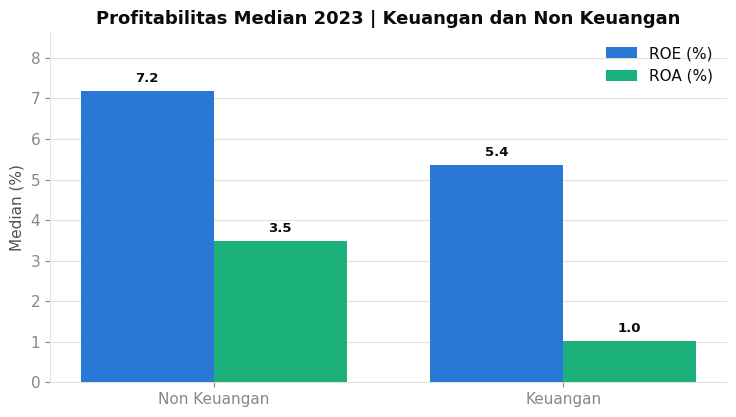

In [8]:
base = y23[~y23["neg_equity"]].copy()
grp = base.groupby("kelompok")[["ROE", "ROA"]].median().reindex(["Non Keuangan", "Keuangan"])

x = np.arange(len(grp)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.3))
b1 = ax.bar(x - w/2, grp["ROE"], width=w, color=BLUE, zorder=3, label="ROE (%)")
b2 = ax.bar(x + w/2, grp["ROA"], width=w, color=AQUA, zorder=3, label="ROA (%)")
ax.set_xticks(x); ax.set_xticklabels(grp.index)
ax.set_ylabel("Median (%)")
ax.set_title("Profitabilitas Median 2023 | Keuangan dan Non Keuangan")
style_ax(ax); bar_labels(ax, b1, fmt="{:.1f}", pad=0.15); bar_labels(ax, b2, fmt="{:.1f}", pad=0.15)
ax.set_ylim(0, max(grp.max()) * 1.2)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [9]:
# DuPont: ROE = margin x asset_turnover x equity_mult (median non keuangan 2023)
d = clean[["dupont_margin", "asset_turnover", "equity_mult"]].median()
roe_rekon = d["dupont_margin"] * d["asset_turnover"] * d["equity_mult"] * 100
print("Dekomposisi DuPont | Median emiten non-keuangan 2023")
print(f"  Net Margin        : {d['dupont_margin']*100:6.2f}%")
print(f"  Asset Turnover    : {d['asset_turnover']:6.2f}x")
print(f"  Equity Multiplier : {d['equity_mult']:6.2f}x")
print(f"  -> ROE (rekonstruksi dari median komponen) : {roe_rekon:5.2f}%")
print(f"  -> ROE (median langsung)                   : {clean['ROE'].median():5.2f}%")
print("\n(selisih wajar: median hasil kali != hasil kali median)")

Dekomposisi DuPont | Median emiten non-keuangan 2023
  Net Margin        :   5.84%
  Asset Turnover    :   0.57x
  Equity Multiplier :   1.81x
  -> ROE (rekonstruksi dari median komponen) :  6.00%
  -> ROE (median langsung)                   :  7.19%

(selisih wajar: median hasil kali != hasil kali median)


> **Baca DuPont:** ROE non keuangan yang moderat lebih banyak ditopang **margin** dan **perputaran aset** ketimbang leverage tinggi yang menandakan profitabilitas yang relatif sehat (bukan sekadar hasil menumpuk utang). Emiten dengan ROE tinggi banyak yang karena equity multiplier besar perlu diwaspadai, yaitu ROE rapuh terhadap kenaikan bunga.

## 6. Solvabilitas & Likuiditas (Non Keuangan)

DER dan Current Ratio (hanya untuk non keuangan). Garis acuannya adalah **DER = 1** (utang = modal) dan **Current Ratio = 1** (aset lancar = kewajiban lancar).

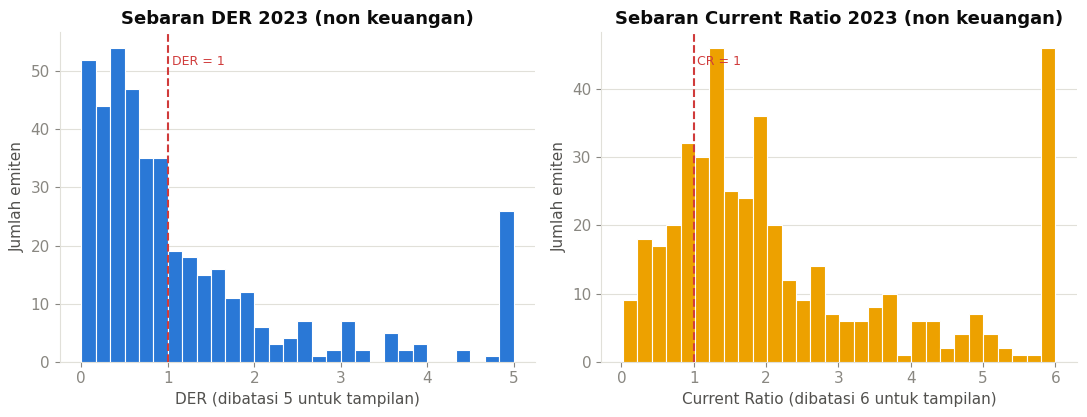

Emiten dgn DER > 1 (utang > modal)        : 162 dari 429 (38%)
Emiten dgn Current Ratio < 1 (likuiditas ketat) : 90 dari 429


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

der = clean["DER"].clip(upper=5) 
axes[0].hist(der, bins=30, color=BLUE, zorder=3, edgecolor="white", linewidth=0.8)
axes[0].axvline(1, color=RED, linewidth=1.5, linestyle="--", zorder=4)
axes[0].text(1.05, axes[0].get_ylim()[1]*0.9, "DER = 1", color=RED, fontsize=9)
axes[0].set_title("Sebaran DER 2023 (non keuangan)")
axes[0].set_xlabel("DER (dibatasi 5 untuk tampilan)"); axes[0].set_ylabel("Jumlah emiten")
style_ax(axes[0])

cr = clean["CurrentRatio"].clip(upper=6)
axes[1].hist(cr, bins=30, color=AMBER, zorder=3, edgecolor="white", linewidth=0.8)
axes[1].axvline(1, color=RED, linewidth=1.5, linestyle="--", zorder=4)
axes[1].text(1.05, axes[1].get_ylim()[1]*0.9, "CR = 1", color=RED, fontsize=9)
axes[1].set_title("Sebaran Current Ratio 2023 (non keuangan)")
axes[1].set_xlabel("Current Ratio (dibatasi 6 untuk tampilan)"); axes[1].set_ylabel("Jumlah emiten")
style_ax(axes[1])

plt.tight_layout(); plt.show()

n_high_der = int((clean["DER"] > 1).sum())
n_low_cr   = int((clean["CurrentRatio"] < 1).sum())
print(f"Emiten dgn DER > 1 (utang > modal)        : {n_high_der} dari {len(clean)} ({n_high_der/len(clean):.0%})")
print(f"Emiten dgn Current Ratio < 1 (likuiditas ketat) : {n_low_cr} dari {clean['CurrentRatio'].notna().sum()}")

## 7. Peer Comparison antar Sektor (2023)

Inti dari tahap ini adalah membandingkan rasio **antar 11 sektor riil** (dari metadata). Sektor `Unknown` dikecualikan. Basis nya adalah emiten **non-keuangan dengan ekuitas positif**.

In [12]:
peer = clean[clean["sector"].notna() & (clean["sector"] != "Unknown")].copy()

sector_tbl = peer.groupby("sector").agg(
    n=("symbol", "size"),
    ROE_med=("ROE", "median"),
    ROA_med=("ROA", "median"),
    NetMargin_med=("NetMargin", "median"),
    DER_med=("DER", "median"),
    CurrentRatio_med=("CurrentRatio", "median"),
).round(2).sort_values("ROE_med", ascending=False)
sector_tbl

,n,ROE_med,ROA_med,NetMargin_med,DER_med,CurrentRatio_med
sector,,,,,,
Energy,33,14.25,9.19,8.95,0.99,1.44
Consumer Defensive,67,11.75,5.76,4.48,0.85,1.74
Technology,8,10.32,5.30,3.73,0.53,2.69
Utilities,8,9.63,3.94,16.08,1.07,1.81
Industrials,69,8.41,4.26,7.38,0.71,1.78
Healthcare,25,7.75,3.04,4.53,0.45,2.31
Basic Materials,53,6.86,4.03,6.53,0.73,1.44
Financial Services,20,4.82,2.32,26.11,0.92,5.41
Communication Services,28,4.53,2.09,3.85,0.64,1.96


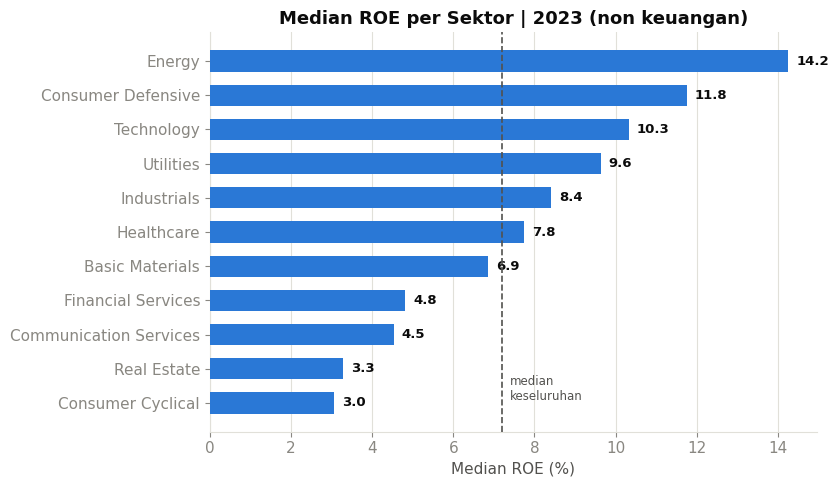

In [13]:
# ROE median per sektor (barh)
s = sector_tbl["ROE_med"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [RED if v < 0 else BLUE for v in s.values]
bars = ax.barh(s.index, s.values, color=colors, zorder=3, height=0.62)
ax.axvline(peer["ROE"].median(), color=INK_2, linewidth=1.2, linestyle="--", zorder=4)
ax.text(peer["ROE"].median()+0.2, 0.1, "median\nkeseluruhan", color=INK_2, fontsize=8.5)
ax.set_title("Median ROE per Sektor | 2023 (non keuangan)")
ax.set_xlabel("Median ROE (%)")
style_ax(ax, grid_axis="x"); bar_labels(ax, bars, fmt="{:.1f}", horizontal=True, pad=0.2)
plt.tight_layout(); plt.show()

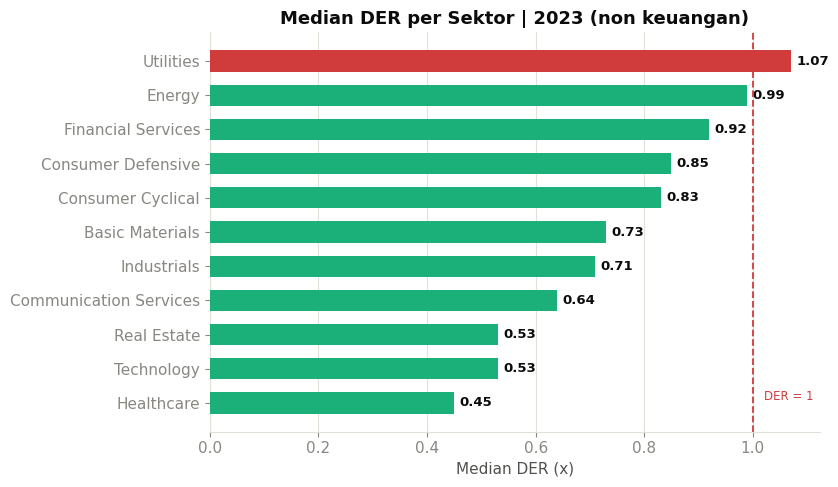

In [ ]:
# DER median per sektor
s = sector_tbl["DER_med"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [RED if v > 1 else AQUA for v in s.values]
bars = ax.barh(s.index, s.values, color=colors, zorder=3, height=0.62)
ax.axvline(1, color=RED, linewidth=1.3, linestyle="--", zorder=4)
ax.text(1.02, 0.1, "DER = 1", color=RED, fontsize=8.5)
ax.set_title("Median DER per Sektor | 2023 (non keuangan)")
ax.set_xlabel("Median DER (x)")
style_ax(ax, grid_axis="x"); bar_labels(ax, bars, fmt="{:.2f}", horizontal=True, pad=0.01)
plt.tight_layout(); plt.show()

> **Peta sektor 2023.** *Energy* dan *Consumer Defensive* memimpin profitabilitas dengan ROE median tertinggi, selaras dengan komoditas yang booming pada tahun 2022–2023 dan sifat defensif konsumsi pokok. *Real Estate* dan *Consumer Cyclical* paling lesu. Dari sisi utang, *Healthcare*, *Technology*, dan *Real Estate* paling konservatif dengan DER yang rendah, sedangkan *Utilities* dan *Energy* paling banyak memakai utang (hal ini wajar karena keduanya padat modal)

## 8. Tren Rasio dari tahun 2020 ke tahun 2023

Arah gerak rasio median (non-keuangan, ekuitas positif) sepanjang empat tahun untuk mengetahui apakah profitabilitas membaik dan struktur utang menguat?

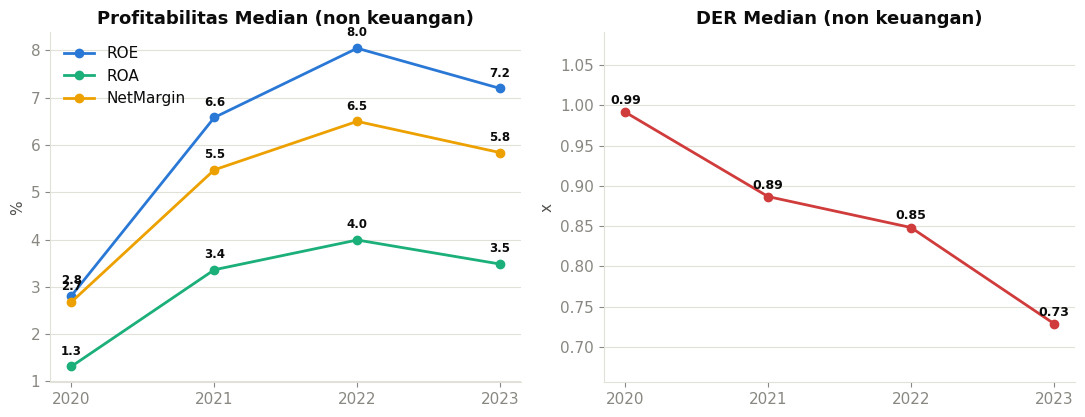

,ROE,ROA,NetMargin,DER
year,,,,
2020,2.81,1.32,2.68,0.99
2021,6.58,3.36,5.47,0.89
2022,8.04,3.99,6.50,0.85
2023,7.19,3.48,5.84,0.73


In [15]:
trend_base = piv[(~piv["is_financial"]) & (~piv["neg_equity"])]
trend = trend_base.groupby("year")[["ROE", "ROA", "NetMargin", "DER"]].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# Profitabilitas
for col, c in [("ROE", BLUE), ("ROA", AQUA), ("NetMargin", AMBER)]:
    axes[0].plot(trend.index, trend[col], marker="o", color=c, linewidth=2, label=col, zorder=3)
    for xi, yi in zip(trend.index, trend[col]):
        axes[0].text(xi, yi+0.25, f"{yi:.1f}", ha="center", fontsize=8.5, color=INK, fontweight="600")
axes[0].set_title("Profitabilitas Median (non keuangan)")
axes[0].set_ylabel("%"); style_ax(axes[0]); axes[0].legend(frameon=False)

# DER
axes[1].plot(trend.index, trend["DER"], marker="o", color=RED, linewidth=2, zorder=3)
for xi, yi in zip(trend.index, trend["DER"]):
    axes[1].text(xi, yi+0.01, f"{yi:.2f}", ha="center", fontsize=9, color=INK, fontweight="600")
axes[1].set_title("DER Median (non keuangan)")
axes[1].set_ylabel("x"); style_ax(axes[1])
axes[1].set_ylim(trend["DER"].min()*0.9, trend["DER"].max()*1.1)

plt.tight_layout(); plt.show()
trend.round(2)

> **Pemulihan dan deleveraging.** Profitabilitas median naik tegas dari 2020 (titik terendah pandemi) ke 2022–2023, sementara DER median cenderung **turun**, sedangkan emiten non keuangan umumnya menjadi lebih untung sekaligus lebih sedikit bergantung pada utang.

## 9. Contoh Screening Emiten yang Layak di tahun 2023

Demonstrasi bagaimana rasio dipakai untuk **menyaring**, persis kebutuhan SOKO Financial.
Kriteria sederhana & konservatif pada emiten non keuangan 2023:

- **ROE ≥ 15%**: Profitabilitas modal kuat
- **DER ≤ 1**: Utang tidak melebihi modal
- **Net Margin > 0**: Benar-benar mencetak laba
- **Current Ratio ≥ 1**: Likuiditas aman

Ini contoh kriteria, bukan rekomendasi investasi.

In [16]:
screen = clean[
    (clean["ROE"] >= 15) &
    (clean["DER"] <= 1) &
    (clean["NetMargin"] > 0) &
    (clean["CurrentRatio"] >= 1)
].copy()

print(f"Lolos screening: {len(screen)} dari {len(clean)} emiten non keuangan "
      f"({len(screen)/len(clean):.1%})")
print()
print("Sebaran per sektor:")
print(screen["sector"].value_counts().to_string())

cols = ["symbol", "company_name", "sector", "ROE", "ROA", "NetMargin", "DER", "CurrentRatio"]
screen.sort_values("ROE", ascending=False)[cols].head(15).round(2).set_index("symbol")

Lolos screening: 65 dari 429 emiten non keuangan (15.2%)

Sebaran per sektor:
sector
Consumer Defensive        14
Industrials               13
Energy                    12
Basic Materials            9
Healthcare                 5
Real Estate                4
Consumer Cyclical          4
Financial Services         1
Communication Services     1
Unknown                    1
Technology                 1


,company_name,sector,ROE,ROA,NetMargin,DER,CurrentRatio
symbol,,,,,,,
GEMS,PT Golden Energy Mines Tbk,Energy,79.29,39.51,17.86,0.99,1.37
BSSR,PT Baramulti Suksessarana Tbk,Energy,66.92,39.73,14.31,0.68,1.38
BYAN,PT Bayan Resources Tbk.,Energy,65.84,35.96,34.58,0.78,1.42
ADMR,PT Alamtri Minerals Indonesia Tbk,Basic Materials,45.17,26.01,40.61,0.67,4.22
MCOL,PT Prima Andalan Mandiri Tbk,Energy,40.94,30.59,24.84,0.29,3.41
SMMT,PT Golden Eagle Energy Tbk,Energy,32.81,24.25,24.05,0.28,1.08
PBSA,PT Paramita Bangun Sarana Tbk,Industrials,32.30,24.24,33.67,0.33,3.11
DRMA,PT Dharma Polimetal Tbk,Consumer Cyclical,32.14,18.07,11.04,0.71,1.61
AMOR,PT Ashmore Asset Management Indonesia Tbk,Financial Services,31.86,25.69,28.52,0.24,5.89


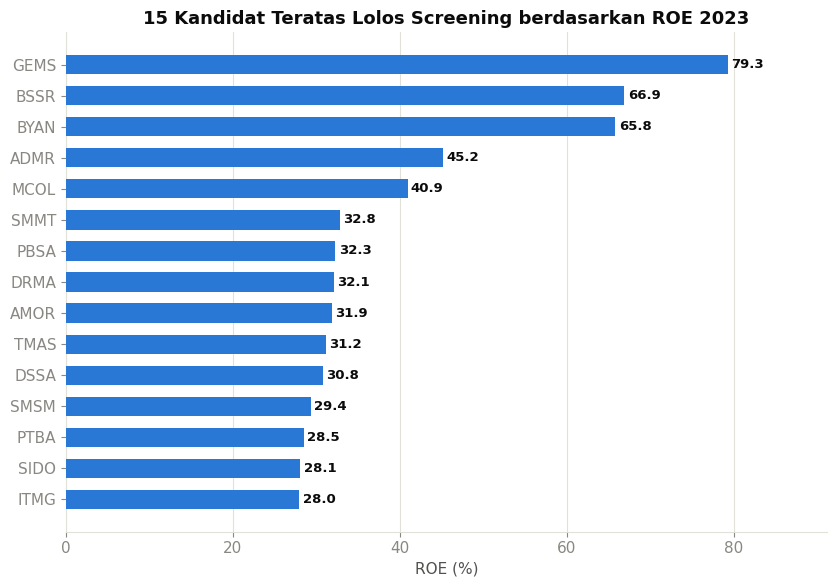

In [17]:
# 15 kandidat ROE tertinggi yang lolos screening
top = screen.sort_values("ROE", ascending=False).head(15).sort_values("ROE")
fig, ax = plt.subplots(figsize=(8.5, 6))
bars = ax.barh(top["symbol"], top["ROE"], color=BLUE, zorder=3, height=0.62)
ax.set_title("15 Kandidat Teratas Lolos Screening berdasarkan ROE 2023")
ax.set_xlabel("ROE (%)")
style_ax(ax, grid_axis="x"); bar_labels(ax, bars, fmt="{:.1f}", horizontal=True, pad=0.4)
ax.set_xlim(0, top["ROE"].max()*1.15)
plt.tight_layout(); plt.show()

## 10. Ringkasan Temuan
- **Rasio dihitung** dari gabungan Balance Sheet dan Income Statement yang terdiri dari profitabilitas (ROE, ROA,Net Margin), solvabilitas (DER), likuiditas (Current Ratio), serta dekomposisi **DuPont**.
- **Pemisahan wajib.** Emiten keuangan (~87 di 2023) dipisah dari non-keuangan, emiten berekuitas negatif (~20) dikecualikan dari ROE/DER agar tidak menyesatkan.
- **Pada Profitabilitas 2023** emiten non keuangan tipikal, dengan ROE median ~7%, ROA ~3,5%, Net Margin ~6%. DuPont menunjukkan ROE lebih ditopang **margin & perputaran aset** ketimbang leverage tanda relatif sehat.
- **Peer antar sektor:** *Energy* & *Consumer Defensive* paling profitable dan *Real Estate* & *Consumer Cyclical* terlemah. Utang tertinggi di *Utilities* & *Energy* (padat modal), terendah di *Healthcare* & *Technology*.
- **Tren 2020→2023:** profitabilitas pulih dari dasar pandemi sambil **DER menurun**, non keuangan makin sehat (lebih untung dan lebih sedikit utang).
- **Screening** (ROE≥15%, DER≤1, margin>0, CR≥1) menyaring sekelompok kecil emiten unggulan yang menunjukkan rasio ini langsung bisa jadi mesin penyaring awal untuk SOKO Financial.

<!-- ## Penutup Rangkaian EDA

Tiga notebook ini membentuk alur lengkap: (1) kualitas & struktur data, (2) breakdown metrik
kunci & tren, (3) rasio keuangan & peer comparison per sektor. Keluarannya siap jadi fondasi
untuk dashboard screening / scoring emiten (lihat app.py). -->